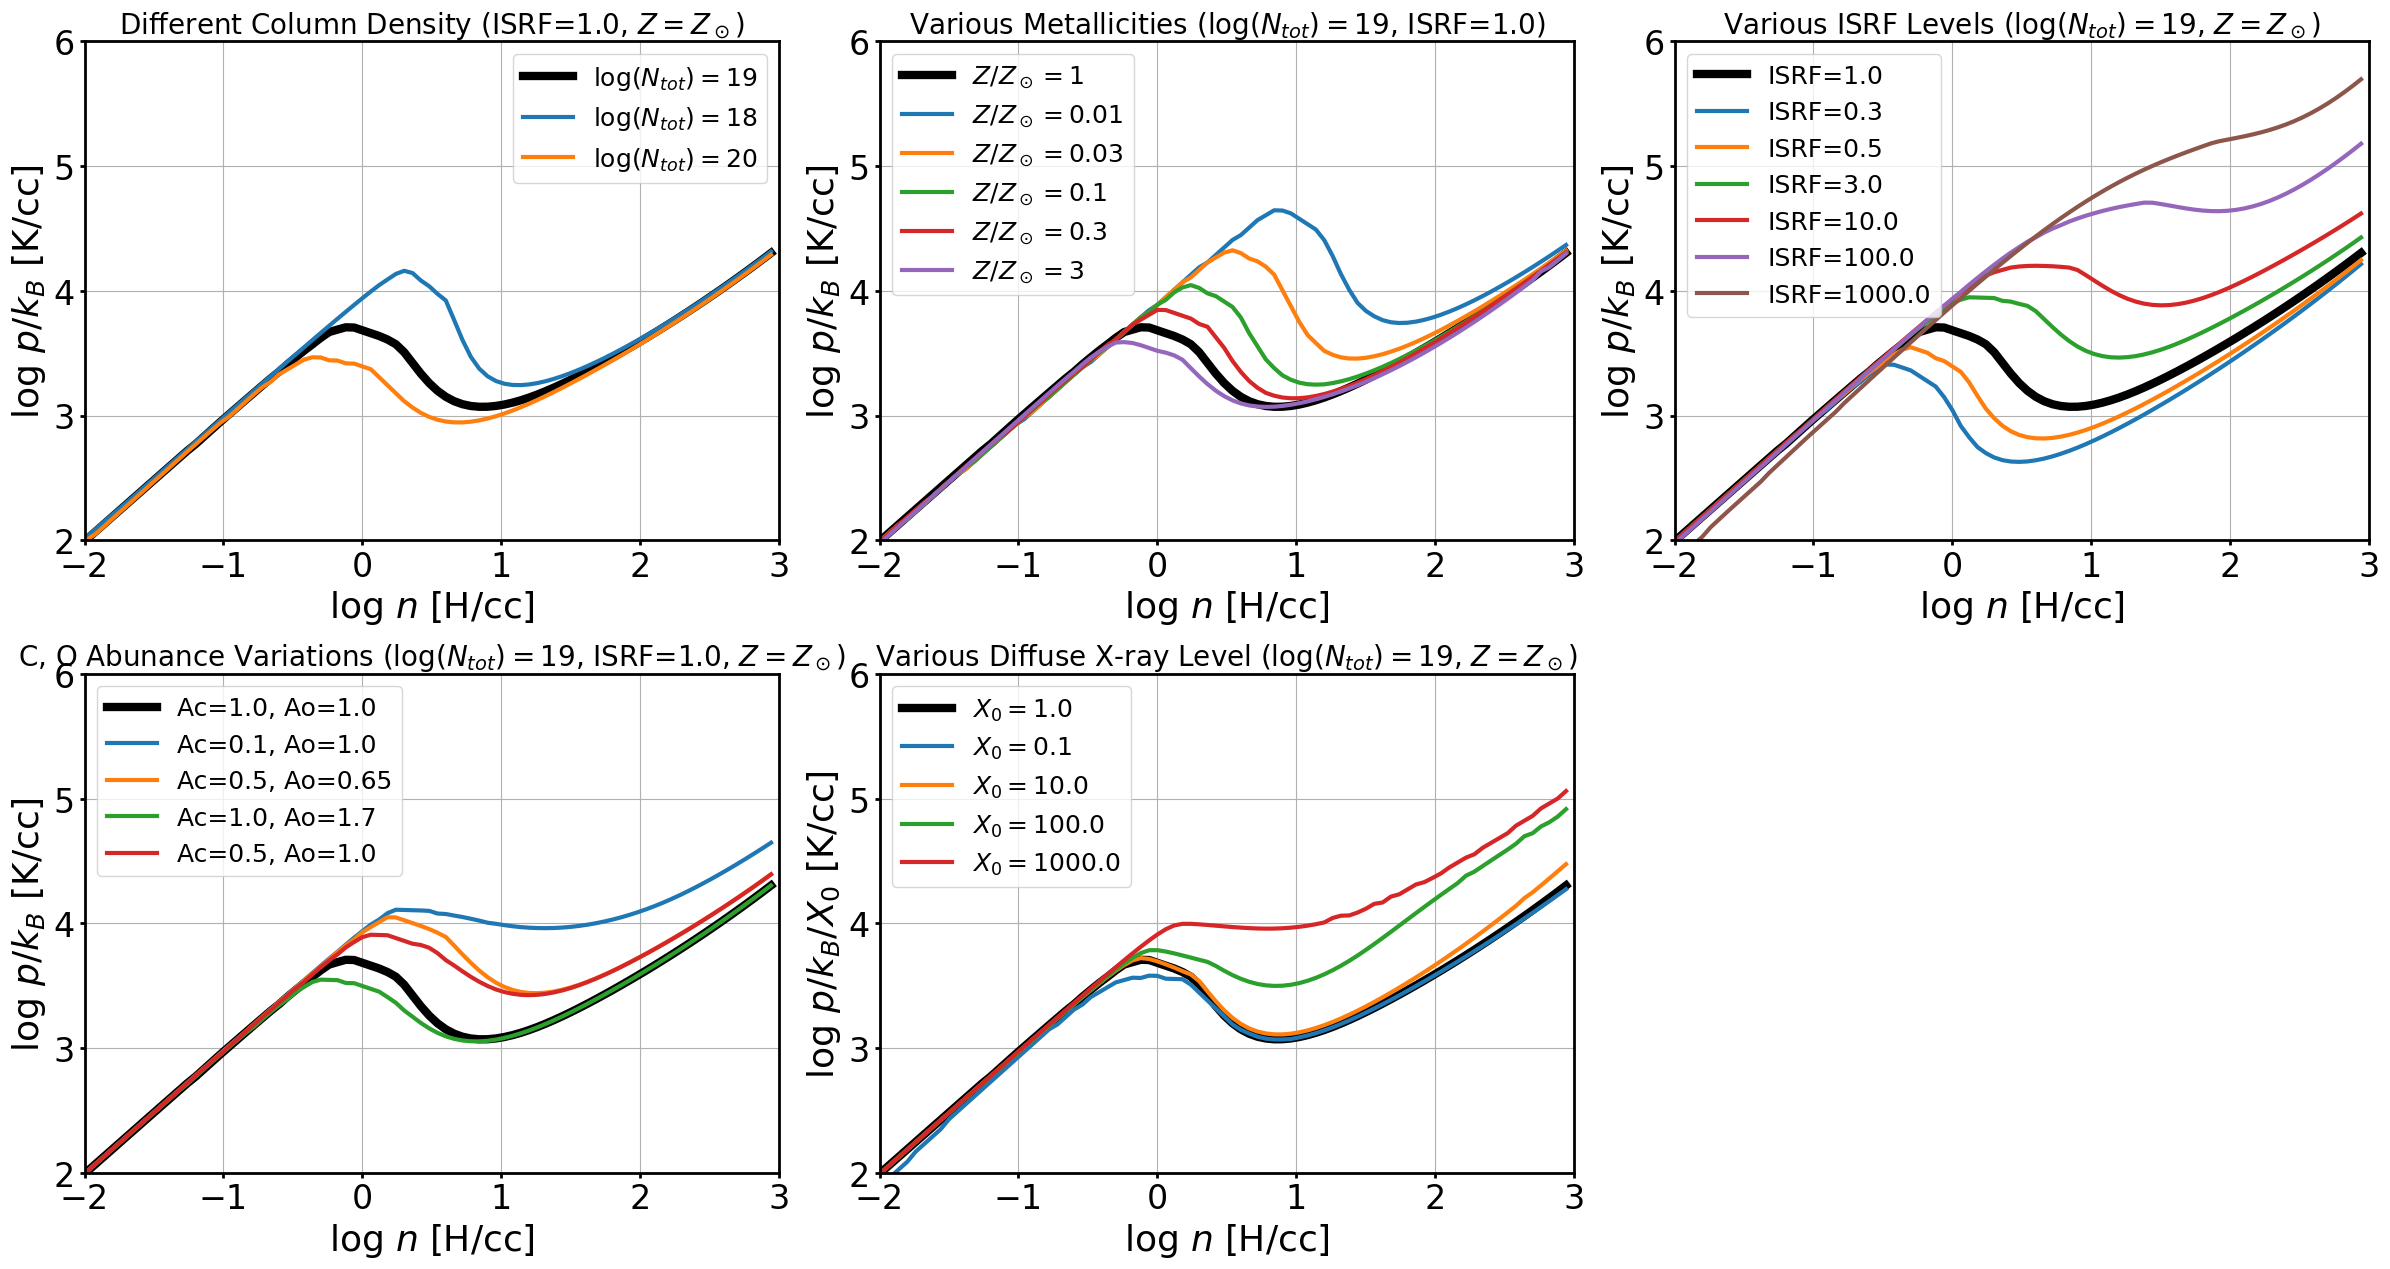

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# プロット全体の設定
parameters = {
    'axes.linewidth': 2.0,
    'axes.labelsize': 26,
    'xtick.labelsize': 24,
    'ytick.labelsize': 24,
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'axes.titlesize': 20,
    'figure.titlesize': 24,
    'legend.fontsize': 18,
    'figure.figsize': [10, 6]
}
plt.rcParams.update(parameters)

# データファイルとタイトルをまとめたリスト（5パネル分）
data_info = [
    # パネル1: ISRF=1.0, 異なる総カラム密度
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00.dat", "$\\log(N_{tot})=19$"),
        ("../out/PostProcessMap_Nt1.0e+18_ISRF1.0_Zs1.0e+00.dat", "$\\log(N_{tot})=18$"),
        ("../out/PostProcessMap_Nt1.0e+20_ISRF1.0_Zs1.0e+00.dat", "$\\log(N_{tot})=20$")
    ], r"Different Column Density (ISRF=1.0, $Z=Z_\odot$)"),
    # パネル2: ISRF=1.0, 異なる金属量
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00.dat", r"$Z/Z_\odot=1$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e-02.dat", r"$Z/Z_\odot=0.01$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs3.0e-02.dat", r"$Z/Z_\odot=0.03$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e-01.dat", r"$Z/Z_\odot=0.1$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs3.0e-01.dat", r"$Z/Z_\odot=0.3$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs3.0e+00.dat", r"$Z/Z_\odot=3$")
    ], r"Various Metallicities ($\log(N_{tot})=19$, ISRF=1.0)"),
    # パネル3: 異なるISRFレベル（$\\log(N_{tot})=19$）
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00.dat", "ISRF=1.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF0.3_Zs1.0e+00.dat", "ISRF=0.3"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF0.5_Zs1.0e+00.dat", "ISRF=0.5"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF3.0_Zs1.0e+00.dat", "ISRF=3.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF10.0_Zs1.0e+00.dat", "ISRF=10.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF100.0_Zs1.0e+00.dat", "ISRF=100.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1000.0_Zs1.0e+00.dat", "ISRF=1000.0")
    ], r"Various ISRF Levels ($\log(N_{tot})=19$, $Z=Z_\odot$)"),
    # パネル4: Ac, Aoの違い
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac1.0e+00_Ao1.0e+00.dat", "Ac=1.0, Ao=1.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac1.0e-01_Ao1.0e+00.dat", "Ac=0.1, Ao=1.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac5.0e-01_Ao6.5e-01.dat", "Ac=0.5, Ao=0.65"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac1.0e+00_Ao1.7e+00.dat", "Ac=1.0, Ao=1.7"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac5.0e-01_Ao1.0e+00.dat", "Ac=0.5, Ao=1.0")
    ], r"C, O Abunance Variations ($\log(N_{tot})=19$, ISRF=1.0, $Z=Z_\odot$)"),
    # パネル5: X0の違い
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Xo1.0.dat", "$X_0=1.0$", 1.0),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF0.1_Zs1.0e+00_Xo0.1.dat", "$X_0=0.1$", 0.1),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF10.0_Zs1.0e+00_Xo10.0.dat", "$X_0=10.0$", 10.0),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF100.0_Zs1.0e+00_Xo100.0.dat", "$X_0=100.0$", 100.0),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1000.0_Zs1.0e+00_Xo1000.0.dat", "$X_0=1000.0$", 1000.0)
    ], r"Various Diffuse X-ray Level ($\log(N_{tot})=19$, $Z=Z_\odot$)")
]

# 3行2列のグリッドを作成（計6パネル）、最後のパネルは非表示にする
rows, cols = 2, 3
size = 8
fig, axs = plt.subplots(rows, cols, figsize=(cols * size, 0.8 * rows * size))
axs = axs.flatten()

# 各パネルのプロット
for idx, (ax, (file_title_pairs, plot_title)) in enumerate(zip(axs, data_info)):
    # 各パネル内で、1本目だけ lw=6, color=黒、以降は lw=3 に設定
    for j, file_title in enumerate(file_title_pairs):
        if len(file_title) == 3:
            file_path, title, X0 = file_title
            data = pd.read_csv(file_path, sep=r'\s+', header=None)
            x = np.log10(data.iloc[:, 12] / X0)
            y = np.log10(data.iloc[:, 8] * data.iloc[:, 12] / X0)
        else:
            file_path, title = file_title
            data = pd.read_csv(file_path, sep=r'\s+', header=None)
            x = np.log10(data.iloc[:, 12])
            y = np.log10(data.iloc[:, 8] * data.iloc[:, 12])
        lw_val = 6 if j == 0 else 3
        color_val = 'k' if j == 0 else None
        ax.plot(x, y, lw=lw_val, label=title, color=color_val)
    ax.set_title(plot_title)
    ax.set_xlabel("log $n$ [H/cc]")
    # 5番目のパネルのみ y 軸ラベルを変更
    if idx == 4:
        ax.set_ylabel("log $p/k_B/X_0$ [K/cc]")
    else:
        ax.set_ylabel("log $p/k_B$ [K/cc]")
    ax.set_xlim([-2, 3])
    ax.set_ylim([2, 6])
    ax.legend()
    ax.grid(True)

# 余分な6番目のパネルは非表示にする
axs[-1].axis('off')

plt.subplots_adjust(hspace=0.4)
plt.tight_layout()
plt.show()

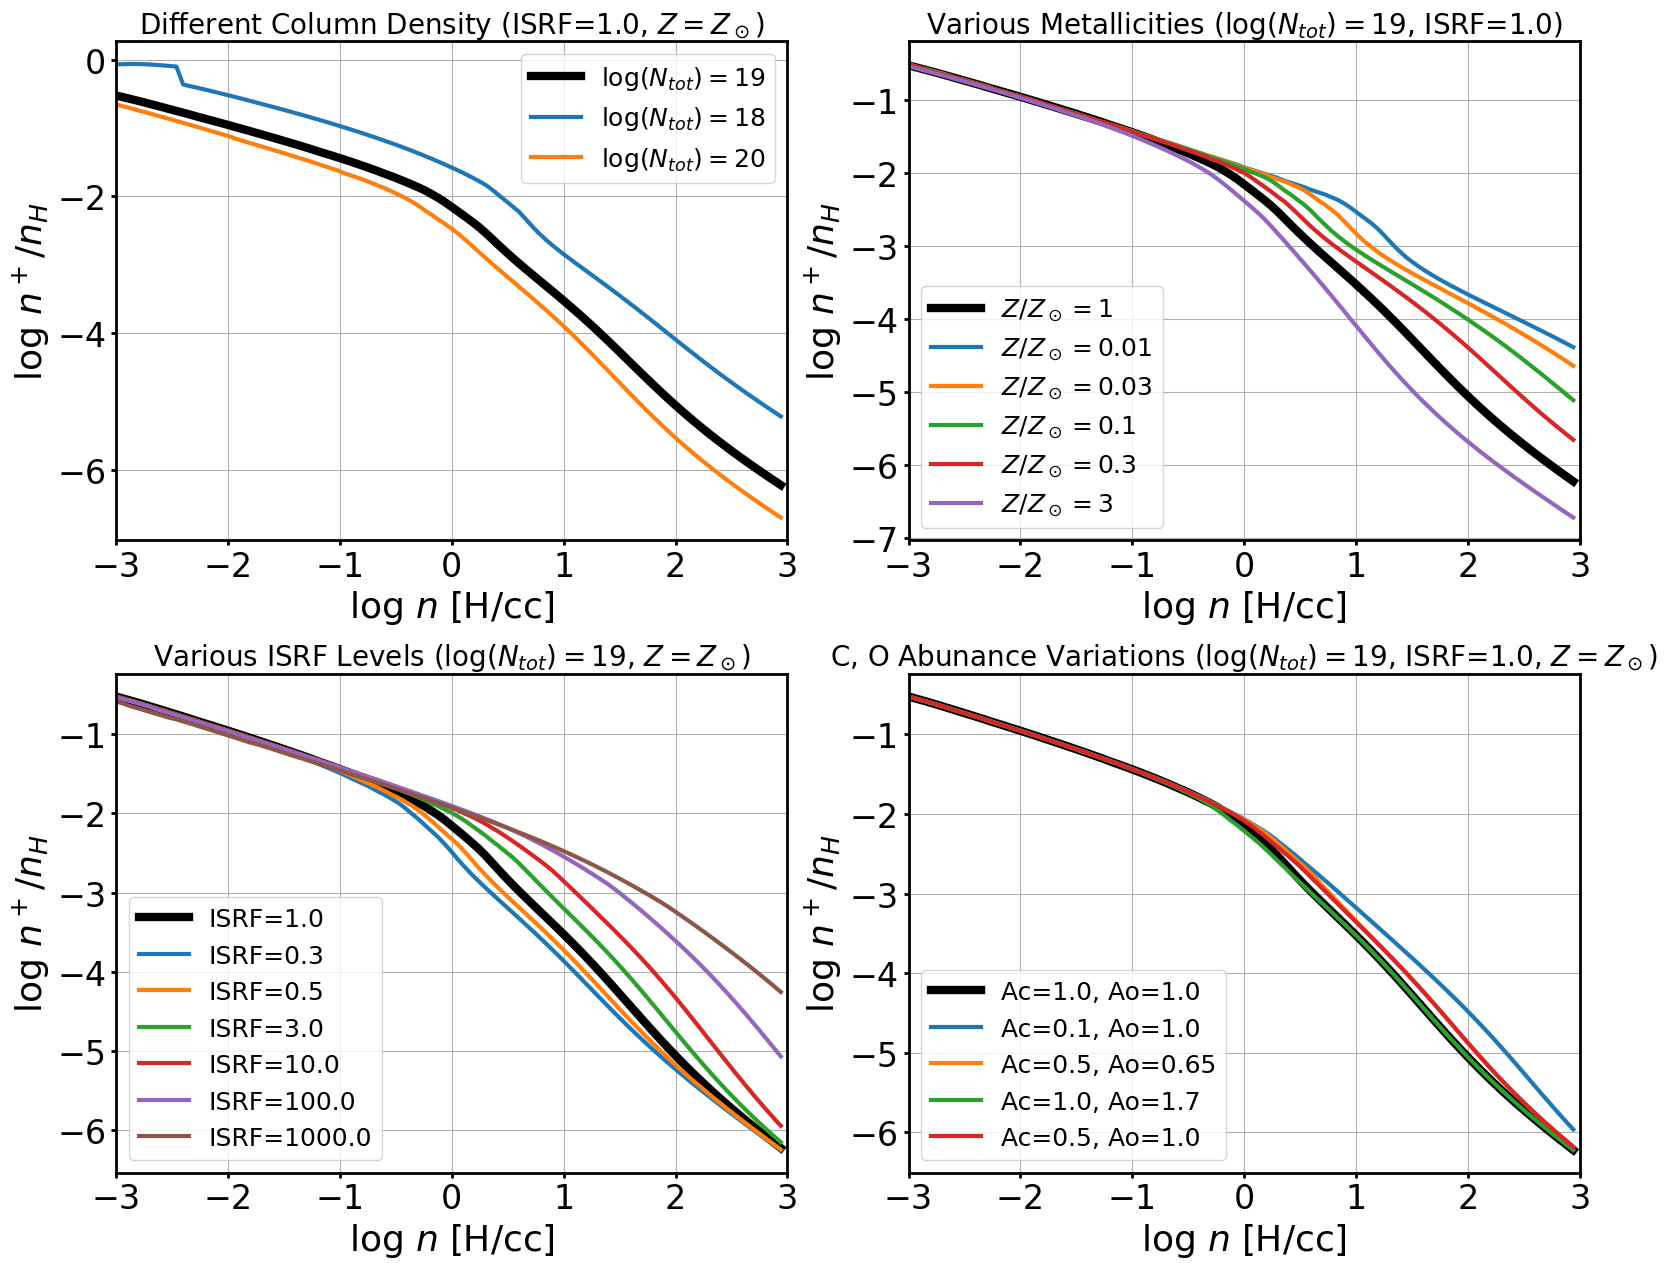

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# プロット全体の設定
parameters = {
    'axes.linewidth': 2.0,
    'axes.labelsize': 26,
    'xtick.labelsize': 24,
    'ytick.labelsize': 24,
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'axes.titlesize': 20,
    'figure.titlesize': 24,
    'legend.fontsize': 18,
    'figure.figsize': [10, 6]
}
plt.rcParams.update(parameters)

# データファイルとタイトルをまとめたリスト（5パネル分）
data_info = [
    # パネル1: ISRF=1.0, 異なる総カラム密度
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00.dat", "$\\log(N_{tot})=19$"),
        ("../out/PostProcessMap_Nt1.0e+18_ISRF1.0_Zs1.0e+00.dat", "$\\log(N_{tot})=18$"),
        ("../out/PostProcessMap_Nt1.0e+20_ISRF1.0_Zs1.0e+00.dat", "$\\log(N_{tot})=20$")
    ], r"Different Column Density (ISRF=1.0, $Z=Z_\odot$)"),
    # パネル2: ISRF=1.0, 異なる金属量
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00.dat", r"$Z/Z_\odot=1$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e-02.dat", r"$Z/Z_\odot=0.01$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs3.0e-02.dat", r"$Z/Z_\odot=0.03$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e-01.dat", r"$Z/Z_\odot=0.1$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs3.0e-01.dat", r"$Z/Z_\odot=0.3$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs3.0e+00.dat", r"$Z/Z_\odot=3$")
    ], r"Various Metallicities ($\log(N_{tot})=19$, ISRF=1.0)"),
    # パネル3: 異なるISRFレベル（$\\log(N_{tot})=19$）
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00.dat", "ISRF=1.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF0.3_Zs1.0e+00.dat", "ISRF=0.3"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF0.5_Zs1.0e+00.dat", "ISRF=0.5"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF3.0_Zs1.0e+00.dat", "ISRF=3.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF10.0_Zs1.0e+00.dat", "ISRF=10.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF100.0_Zs1.0e+00.dat", "ISRF=100.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1000.0_Zs1.0e+00.dat", "ISRF=1000.0")
    ], r"Various ISRF Levels ($\log(N_{tot})=19$, $Z=Z_\odot$)"),
    # パネル4: Ac, Aoの違い
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac1.0e+00_Ao1.0e+00.dat", "Ac=1.0, Ao=1.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac1.0e-01_Ao1.0e+00.dat", "Ac=0.1, Ao=1.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac5.0e-01_Ao6.5e-01.dat", "Ac=0.5, Ao=0.65"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac1.0e+00_Ao1.7e+00.dat", "Ac=1.0, Ao=1.7"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac5.0e-01_Ao1.0e+00.dat", "Ac=0.5, Ao=1.0")
    ], r"C, O Abunance Variations ($\log(N_{tot})=19$, ISRF=1.0, $Z=Z_\odot$)"),
]

# 3行2列のグリッドを作成（計6パネル）、最後のパネルは非表示にする
rows, cols = 2, 2
size = 8
fig, axs = plt.subplots(rows, cols, figsize=(cols * size, 0.8 * rows * size))
axs = axs.flatten()

# 各パネルのプロット
for idx, (ax, (file_title_pairs, plot_title)) in enumerate(zip(axs, data_info)):
    # 各パネル内で、1本目だけ lw=6, color=黒、以降は lw=3 に設定
    for j, file_title in enumerate(file_title_pairs):
        file_path, title = file_title
        data = pd.read_csv(file_path, sep=r'\s+', header=None)
        x = np.log10(data.iloc[:, 12])
        y = np.log10(data.iloc[:, 17] / data.iloc[:, 12])
        lw_val = 6 if j == 0 else 3
        color_val = 'k' if j == 0 else None
        ax.plot(x, y, lw=lw_val, label=title, color=color_val)
    ax.set_title(plot_title)
    ax.set_xlabel("log $n$ [H/cc]")
    # 5番目のパネルのみ y 軸ラベルを変更
    ax.set_ylabel("log $n^+/n_H$")
    ax.set_xlim([-3, 3])
    #ax.set_ylim([2, 6])
    ax.legend(loc="best")
    ax.grid(True)

# 余分な6番目のパネルは非表示にする
#axs[-1].axis('off')

plt.subplots_adjust(hspace=0.4)
plt.tight_layout()
plt.show()

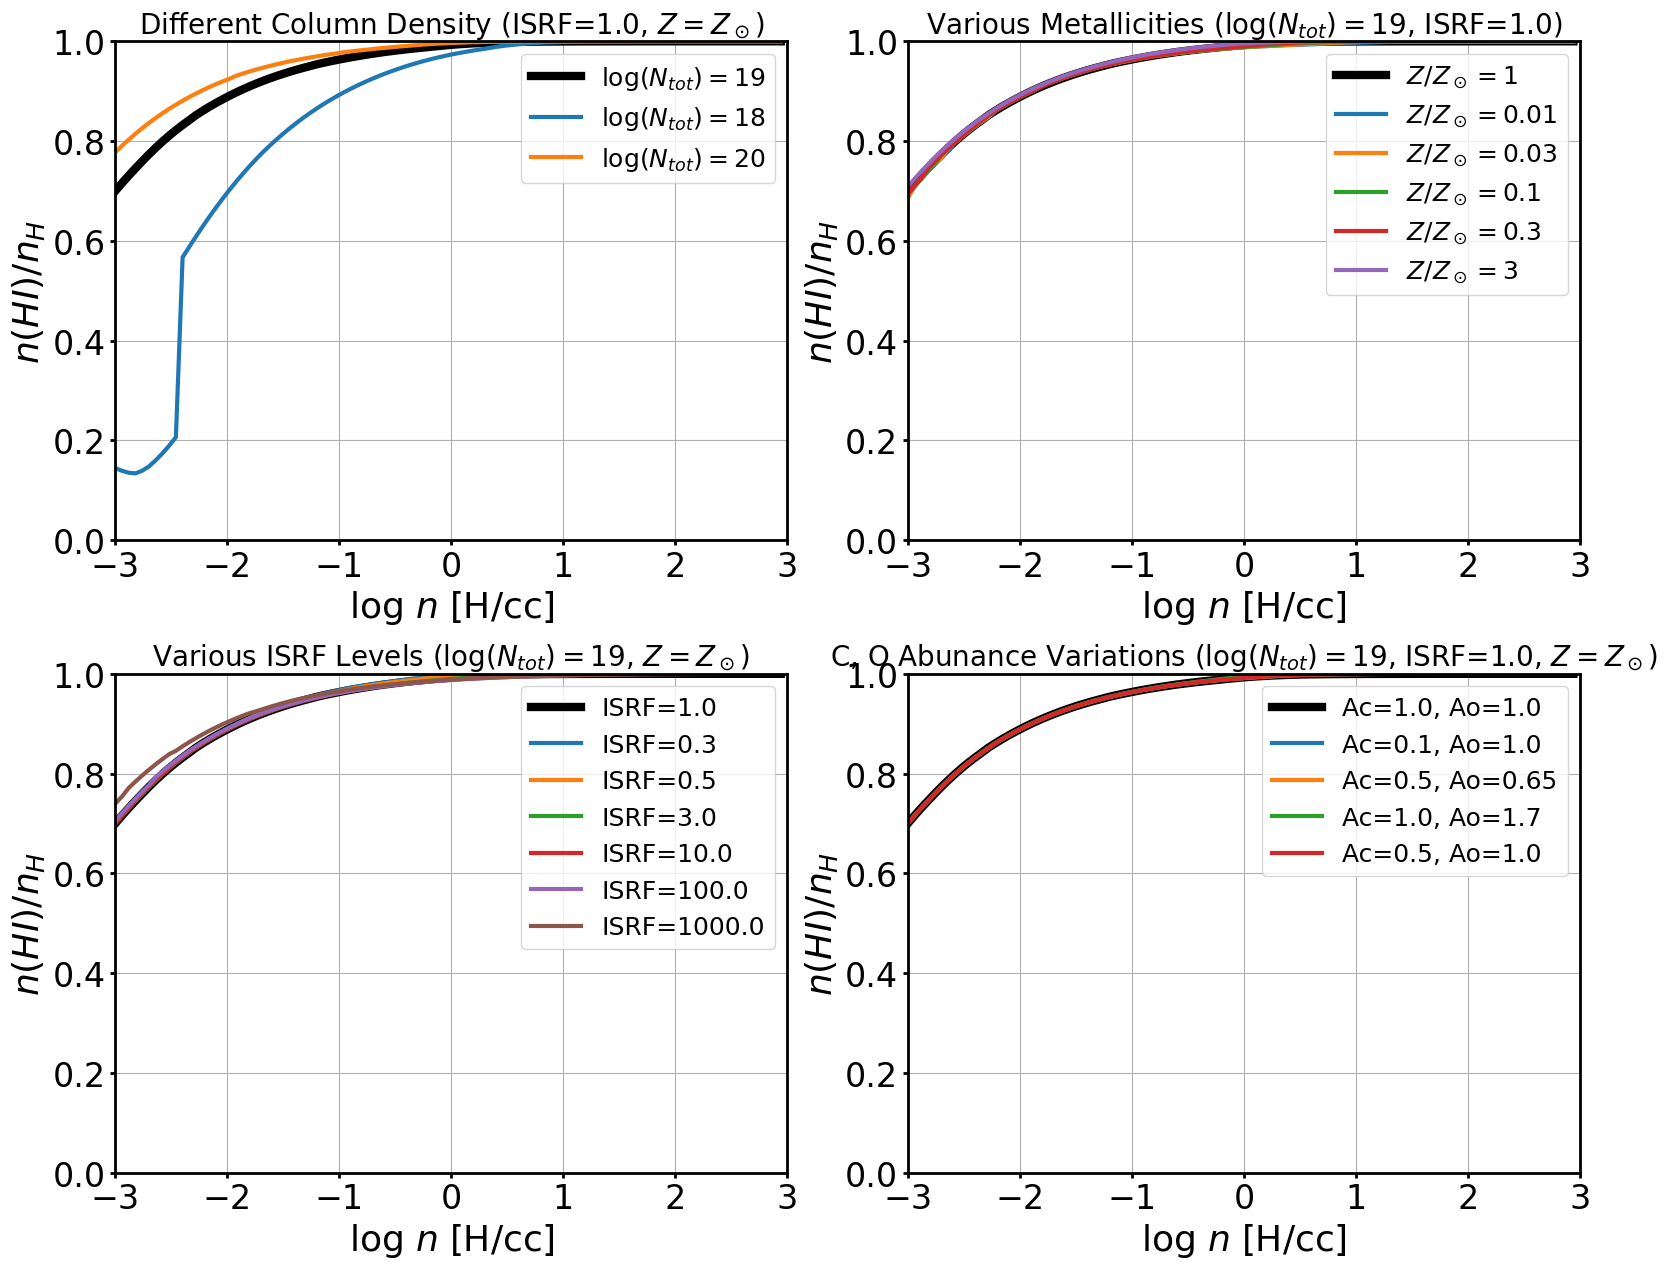

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# プロット全体の設定
parameters = {
    'axes.linewidth': 2.0,
    'axes.labelsize': 26,
    'xtick.labelsize': 24,
    'ytick.labelsize': 24,
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'axes.titlesize': 20,
    'figure.titlesize': 24,
    'legend.fontsize': 18,
    'figure.figsize': [10, 6]
}
plt.rcParams.update(parameters)

# データファイルとタイトルをまとめたリスト（5パネル分）
data_info = [
    # パネル1: ISRF=1.0, 異なる総カラム密度
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00.dat", "$\\log(N_{tot})=19$"),
        ("../out/PostProcessMap_Nt1.0e+18_ISRF1.0_Zs1.0e+00.dat", "$\\log(N_{tot})=18$"),
        ("../out/PostProcessMap_Nt1.0e+20_ISRF1.0_Zs1.0e+00.dat", "$\\log(N_{tot})=20$")
    ], r"Different Column Density (ISRF=1.0, $Z=Z_\odot$)"),
    # パネル2: ISRF=1.0, 異なる金属量
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00.dat", r"$Z/Z_\odot=1$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e-02.dat", r"$Z/Z_\odot=0.01$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs3.0e-02.dat", r"$Z/Z_\odot=0.03$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e-01.dat", r"$Z/Z_\odot=0.1$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs3.0e-01.dat", r"$Z/Z_\odot=0.3$"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs3.0e+00.dat", r"$Z/Z_\odot=3$")
    ], r"Various Metallicities ($\log(N_{tot})=19$, ISRF=1.0)"),
    # パネル3: 異なるISRFレベル（$\\log(N_{tot})=19$）
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00.dat", "ISRF=1.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF0.3_Zs1.0e+00.dat", "ISRF=0.3"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF0.5_Zs1.0e+00.dat", "ISRF=0.5"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF3.0_Zs1.0e+00.dat", "ISRF=3.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF10.0_Zs1.0e+00.dat", "ISRF=10.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF100.0_Zs1.0e+00.dat", "ISRF=100.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1000.0_Zs1.0e+00.dat", "ISRF=1000.0")
    ], r"Various ISRF Levels ($\log(N_{tot})=19$, $Z=Z_\odot$)"),
    # パネル4: Ac, Aoの違い
    ([
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac1.0e+00_Ao1.0e+00.dat", "Ac=1.0, Ao=1.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac1.0e-01_Ao1.0e+00.dat", "Ac=0.1, Ao=1.0"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac5.0e-01_Ao6.5e-01.dat", "Ac=0.5, Ao=0.65"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac1.0e+00_Ao1.7e+00.dat", "Ac=1.0, Ao=1.7"),
        ("../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00_Ac5.0e-01_Ao1.0e+00.dat", "Ac=0.5, Ao=1.0")
    ], r"C, O Abunance Variations ($\log(N_{tot})=19$, ISRF=1.0, $Z=Z_\odot$)"),
]

# 3行2列のグリッドを作成（計6パネル）、最後のパネルは非表示にする
rows, cols = 2, 2
size = 8
fig, axs = plt.subplots(rows, cols, figsize=(cols * size, 0.8 * rows * size))
axs = axs.flatten()

# 各パネルのプロット
for idx, (ax, (file_title_pairs, plot_title)) in enumerate(zip(axs, data_info)):
    # 各パネル内で、1本目だけ lw=6, color=黒、以降は lw=3 に設定
    for j, file_title in enumerate(file_title_pairs):
        file_path, title = file_title
        data = pd.read_csv(file_path, sep=r'\s+', header=None)
        x = np.log10(data.iloc[:, 12])
        #y = np.log10(data.iloc[:, 18] / data.iloc[:, 12])
        y = data.iloc[:, 18] / data.iloc[:, 12]
        lw_val = 6 if j == 0 else 3
        color_val = 'k' if j == 0 else None
        ax.plot(x, y, lw=lw_val, label=title, color=color_val)
    ax.set_title(plot_title)
    ax.set_xlabel("log $n$ [H/cc]")
    # 5番目のパネルのみ y 軸ラベルを変更
    ax.set_ylabel("$n(HI)/n_H$")
    ax.set_xlim([-3, 3])
    ax.set_ylim([0., 1.])
    ax.legend(loc="best")
    ax.grid(True)

# 余分な6番目のパネルは非表示にする
#axs[-1].axis('off')

plt.subplots_adjust(hspace=0.4)
plt.tight_layout()
plt.show()

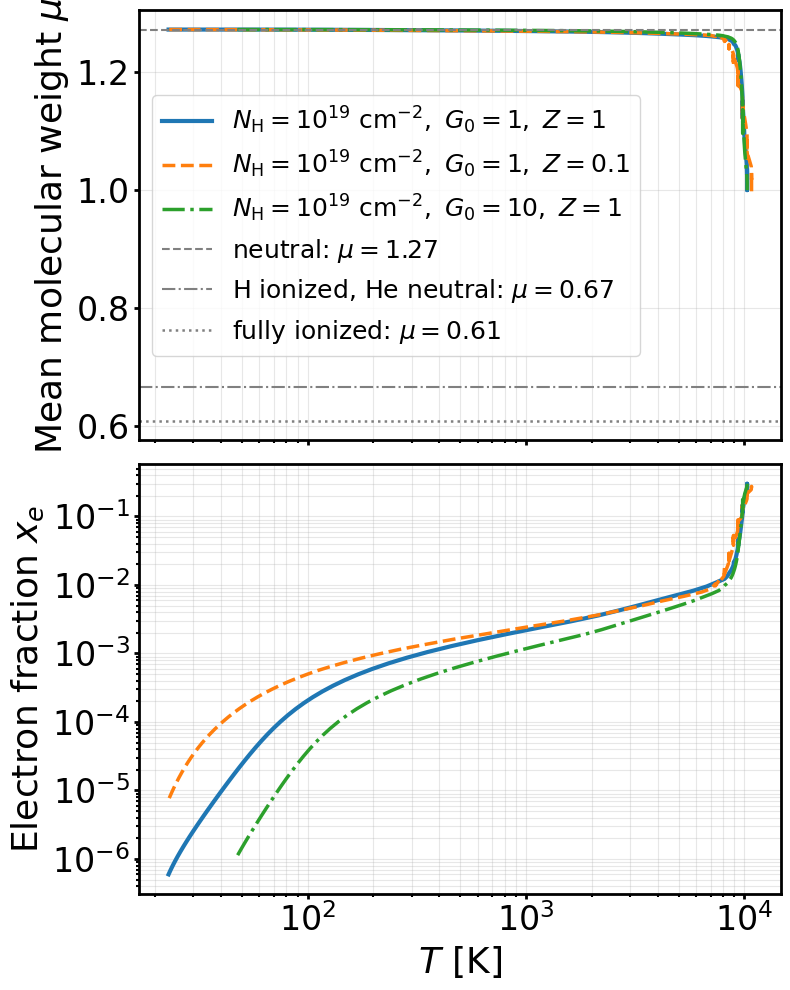

In [15]:
# ============================================================
# Mean molecular weight as a function of temperature
# H2 is not included
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def compute_mu_atomic_wolfire(file_path, y_He=0.1):
    data = pd.read_csv(file_path, sep=r"\s+", header=None)

    T = data.iloc[:, 8].to_numpy()
    nH = data.iloc[:, 12].to_numpy()

    # In this notebook, column 17 is used as the ionized component.
    # We use it as n(H+) and assume charge neutrality: n_e = n(H+).
    nHp = data.iloc[:, 17].to_numpy()

    xe = nHp / nH

    # H2 is not included.
    # Total particle number per H nucleus:
    # HI + H+ gives 1 particle per H nucleus, electrons add xe,
    # and neutral He adds y_He.
    mu = (1.0 + 4.0 * y_He) / (1.0 + y_He + xe)

    return T, mu, xe


# ============================================================
# Plot mu(T) for multiple models
# ============================================================

models_mu = [
    {
        "file": "../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e+00.dat",
        "label": r"$N_{\rm H}=10^{19}\ {\rm cm^{-2}},\ G_0=1,\ Z=1$",
        "ls": "-",
        "lw": 3.0,
    },
    {
        "file": "../out/PostProcessMap_Nt1.0e+19_ISRF1.0_Zs1.0e-01.dat",
        "label": r"$N_{\rm H}=10^{19}\ {\rm cm^{-2}},\ G_0=1,\ Z=0.1$",
        "ls": "--",
        "lw": 2.5,
    },
    {
        "file": "../out/PostProcessMap_Nt1.0e+19_ISRF10.0_Zs1.0e+00.dat",
        "label": r"$N_{\rm H}=10^{19}\ {\rm cm^{-2}},\ G_0=10,\ Z=1$",
        "ls": "-.",
        "lw": 2.5,
    },
]

# Helium abundance by number
y_He = 0.1

mu_neutral = (1.0 + 4.0 * y_He) / (1.0 + y_He)
mu_H_ionized_He_neutral = (1.0 + 4.0 * y_He) / (2.0 + y_He)
mu_fully_ionized = (1.0 + 4.0 * y_He) / (2.0 + 3.0 * y_He)


fig, axes = plt.subplots(2, 1, figsize=(8, 10), sharex=True)

for model in models_mu:
    T, mu, xe = compute_mu_atomic_wolfire(model["file"], y_He=y_He)
    idx = np.argsort(T)

    axes[0].semilogx(T[idx], mu[idx], ls=model["ls"], lw=model["lw"], label=model["label"])
    axes[1].loglog(T[idx], xe[idx], ls=model["ls"], lw=model["lw"], label=model["label"])

axes[0].axhline(mu_neutral, color="gray", ls="--", lw=1.5, label=rf"neutral: $\mu={mu_neutral:.2f}$")
axes[0].axhline(mu_H_ionized_He_neutral, color="gray", ls="-.", lw=1.5, label=rf"H ionized, He neutral: $\mu={mu_H_ionized_He_neutral:.2f}$")
axes[0].axhline(mu_fully_ionized, color="gray", ls=":", lw=1.8, label=rf"fully ionized: $\mu={mu_fully_ionized:.2f}$")

axes[0].set_ylabel(r"Mean molecular weight $\mu$")
axes[1].set_xlabel(r"$T$ [K]")
axes[1].set_ylabel(r"Electron fraction $x_e$")
axes[0].grid(True, which="both", alpha=0.3)
axes[1].grid(True, which="both", alpha=0.3)
axes[0].legend()

plt.tight_layout()
plt.show()